# DFA Cluster Analysis

In [1]:
%load_ext autoreload
%autoreload 2

In [45]:
import itertools
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import sklearn
from sklearn.base import clone
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score, classification_report, cohen_kappa_score, make_scorer
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV
from sklearn.ensemble import RandomForestClassifier
import scipy
from scipy.stats import randint, uniform, loguniform, spearmanr, randint
from scipy.cluster.hierarchy import linkage, fcluster, dendrogram, cophenet
from scipy.spatial.distance import pdist, squareform
from lib.superdataset_utils import (
    load_superdataset,
    DFS_QUESTION_COLS, 
    IDAF_QUESTION_COLS
)
import shap
from umap import UMAP

In [3]:
print(f'pandas version: {pd.__version__}')
print(f'numpy version: {np.__version__}')
print(f'matplotlib version: {matplotlib.__version__}')
print(f'sklearn version: {sklearn.__version__}')
print(f'scipy version: {scipy.__version__}')
print(f'shap version: {shap.__version__}')

pandas version: 2.3.3
numpy version: 2.4.6
matplotlib version: 3.10.6
sklearn version: 1.9.1
scipy version: 1.15.3
shap version: 0.50.0


---

## Helper functions

In [4]:
def stability(X, Z, k, B=50, method="average", metric="cityblock", seed=0):
    """Mean and SD of bootstrap ARI between the full-data k-cluster solution and resample solutions."""
    rng = np.random.default_rng(seed)
    ref = fcluster(Z, k, criterion="maxclust")
    aris = []
    for _ in range(B):
        idx = np.unique(rng.choice(len(X), size=len(X), replace=True))
        Zb = linkage(pdist(X.iloc[idx].to_numpy(), metric=metric), method=method)
        aris.append(adjusted_rand_score(ref[idx], fcluster(Zb, k, criterion="maxclust")))
    return np.mean(aris), np.std(aris)

In [5]:
def cluster_profiles(data, Z, k):
    """
    Cut a hierarchical clustering tree into k clusters and compute each cluster's mean profile.

    Parameters
    ----------
    data : pd.DataFrame
        Respondent-by-item responses (one row per respondent, one column per item).
    Z : np.ndarray
        Linkage matrix returned by scipy's `linkage()` for the same rows as `data`.
    k : int
        Number of clusters to cut the tree into.

    Returns
    -------
    prof : pd.DataFrame
        Item-by-cluster table of mean responses (rows = items, columns = cluster labels 1..k),
        with a final row "n" holding the number of respondents in each cluster.
    labels : np.ndarray
        Cluster label (1..k) of each respondent, in the same row order as `data`.
    """
    # fcluster gives every respondent a cluster label from 1 to k
    labels = fcluster(Z, k, criterion="maxclust")

    # average each item within each cluster, then transpose so items are rows and clusters are columns
    prof = data.groupby(labels).mean().T.round(2)

    # np.bincount counts how many respondents have each label; position 0 is dropped because labels start at 1
    prof.loc["n"] = np.bincount(labels)[1:]
    return prof, labels

In [6]:
def plot_cluster_profiles(ax, prof, clusters, ylabel="Mean response (1–5)",
                          show_xticklabels=True, xtick_fontsize=None, legend_fontsize=None,
                          legend_ncol=None, legend_notes=None, **plot_kwargs):
    """
    Draw the mean-response profiles of selected clusters as lines on a matplotlib Axes.

    Each cluster is one line; the x-axis is the survey items and the y-axis is the mean response.

    Parameters
    ----------
    ax : matplotlib.axes.Axes
        The Axes (plot panel) to draw on.
    prof : pd.DataFrame
        Profile table from `cluster_profiles()` (items as rows, clusters as columns, plus an "n" row).
    clusters : list of int
        Cluster labels to plot, e.g. [4, 5].
    ylabel : str
        Y-axis label; pass "" to leave it blank (useful in a grid of panels).
    show_xticklabels : bool
        If False, the item names under the x-axis are hidden (useful for panels not on the bottom row).
    xtick_fontsize, legend_fontsize : float, optional
        Font sizes for the item names and the legend; None uses matplotlib's default.
    legend_ncol : int, optional
        Number of columns in the legend. None puts all clusters side by side in one row;
        1 stacks them, which leaves room for a larger legend font.
    legend_notes : list of str, optional
        Extra lines of plain text added to the legend after the cluster entries, e.g.
        ["Shape r = 0.84"]. With legend_ncol=1 they appear below the clusters.
    **plot_kwargs
        Extra styling passed to pandas' `DataFrame.plot()` (e.g. markersize=3, linewidth=1).

    Returns
    -------
    ax : matplotlib.axes.Axes
        The same Axes, now containing the plot.
    """
    # cluster sizes come from the "n" row; the remaining rows are the item means to plot
    sizes = prof.loc["n"]
    plot_df = prof.drop(index="n", errors="ignore")[clusters]

    # one line per cluster; the legend is added below so it can show cluster sizes
    plot_df.plot(ax=ax, marker="o", legend=False, **plot_kwargs)

    # put a tick at every item so each item can be labeled
    ax.set_xticks(range(len(plot_df)))
    if show_xticklabels:
        ax.set_xticklabels(plot_df.index, rotation=90, fontsize=xtick_fontsize)
    else:
        ax.tick_params(axis="x", labelbottom=False)
    ax.set_ylabel(ylabel)

    # one legend entry per cluster: the line just drawn for it, labeled e.g. "Cluster 4 (n = 162)"
    handles = list(ax.get_lines())[-len(clusters):]
    labels = [f"Cluster {c} (n = {int(sizes[c])})" for c in clusters]

    # notes are added as text-only entries: a Line2D with no line or marker draws nothing,
    # so only its label shows
    if legend_notes:
        handles += [Line2D([], [], linestyle="none") for _ in legend_notes]
        labels += list(legend_notes)

    # legend sits just above the plot area; by default all entries in one row
    ax.legend(
        handles, labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 1.0),
        ncol=len(clusters) if legend_ncol is None else legend_ncol,
        frameon=False,
        fontsize=legend_fontsize,
    )
    return ax

In [7]:
def plot_pairwise_profiles(prof, clusters, figsize=None, panel_size=(6, 4.5), ylim=(1, 5),
                           legend_fontsize=18, legend_ncol=1, sim_df=None):
    """
    Plot every pair of clusters' profiles in a lower-triangle grid, laid out like a correlation matrix.

    The grid has one row and one column per cluster. The panel at row i, column j (below the
    diagonal, i > j) compares cluster `clusters[j]` with cluster `clusters[i]`. Panels on and above
    the diagonal are left empty: the diagonal would compare a cluster with itself, and the upper
    triangle would repeat the lower one.

    As in a correlation matrix, each row is labeled with its cluster to the left of the left column,
    and each column is labeled with its cluster below the bottom row.

    Parameters
    ----------
    prof : pd.DataFrame
        Profile table from `cluster_profiles()`.
    clusters : list of int
        Cluster labels to compare, e.g. [2, 3, 4, 5, 6, 7].
    figsize : tuple of (width, height), optional
        Size of the whole figure in inches. If None, it is computed from `panel_size`.
    panel_size : tuple of (width, height)
        Size of each panel in inches, used only when `figsize` is None; the figure is then
        (width * number of clusters, height * number of clusters).
    ylim : tuple of (min, max)
        Y-axis range shared by all panels, so their levels can be compared by eye.
    legend_fontsize : float
        Font size of each panel's legend (the "Cluster c (n = ...)" entries).
    legend_ncol : int
        Number of legend columns. 1 stacks the two clusters above each panel, which fits a large
        font; 2 puts them side by side, which needs a smaller font or wider panels.
    sim_df : pd.DataFrame, optional
        Table from `pairwise_similarity_table()`. If given, each panel's legend gets an extra
        line with the shape correlation of that pair, e.g. "Shape r = 0.84".

    Returns
    -------
    fig : matplotlib.figure.Figure
        The figure, so the caller can add a title, save it, or show it.
    """
    n = len(clusters)

    # if no overall size is given, grow the figure with the number of clusters
    if figsize is None:
        figsize = (panel_size[0] * n, panel_size[1] * n)

    # sharex/sharey give all panels the same axes, so tick labels are only needed on the outer panels.
    # squeeze=False keeps `axes` a 2-D array even when n is small.
    fig, axes = plt.subplots(
        n, n,
        figsize=figsize,
        sharex=True, sharey=True, squeeze=False,
        layout="constrained",
    )

    for i, row_cluster in enumerate(clusters):
        for j, col_cluster in enumerate(clusters):
            ax = axes[i, j]

            # diagonal (i == j) and upper triangle (j > i): hide the panel completely
            if j >= i:
                ax.set_axis_off()
                continue

            # shape r for this pair; pairwise_similarity_table() labels pairs "<column> vs <row>"
            notes = None
            if sim_df is not None:
                notes = [f"Shape r = {sim_df.loc[f'{col_cluster} vs {row_cluster}', 'shape_r']:.2f}"]

            plot_cluster_profiles(
                ax, prof, [col_cluster, row_cluster],
                ylabel="Mean response (1–5)" if j == 0 else "",  # y label only on the left column
                show_xticklabels=(i == n - 1),                  # item names only on the bottom row
                xtick_fontsize=7, legend_fontsize=legend_fontsize, legend_ncol=legend_ncol,
                legend_notes=notes,
                markersize=3, linewidth=1,
            )
            ax.set_ylim(*ylim)

            # label the grid like a correlation matrix: the row's cluster to the left of the left column,
            # and the column's cluster below the bottom row (under the item names)
            if j == 0:
                # placed as separate text, left of the y label, so it can be large and bold;
                # x is in Axes coordinates (0 = left edge of the panel, negative = further left)
                ax.text(-0.17, 0.5, f"Cluster {row_cluster}", transform=ax.transAxes,
                        rotation=90, ha="center", va="center", fontsize=18, fontweight="bold")
            if i == n - 1:
                ax.set_xlabel(f"Cluster {col_cluster}", fontsize=18, fontweight="bold")

            # light horizontal grid lines make it easier to read off the levels
            ax.grid(axis="y", alpha=0.3)

    return fig

In [8]:
def profile_similarity(data, labels, a, b, n_boot=1000, seed=0):
    """
    Measure how similar the mean profiles of two clusters are, separating level from shape.

    The mean profile of a cluster is its average response on each item. Two profiles can differ
    in level (one cluster is higher on every item) and in shape (the clusters rise and fall on
    different items), so several complementary measures are returned.

    Parameters
    ----------
    data : pd.DataFrame
        Respondent-by-item responses used to build the clusters (one row per respondent).
    labels : np.ndarray
        Cluster label of each respondent, in the same row order as `data` (from `cluster_profiles()`).
    a, b : int
        The two cluster labels to compare. Differences are computed as b − a.
    n_boot : int
        Number of bootstrap resamples used for the confidence interval of the shape correlation.
    seed : int
        Random seed, so the bootstrap gives the same interval every time it is run.

    Returns
    -------
    dict with keys
        "shape_r"          Pearson correlation between the two mean profiles across items
                           (pattern similarity; ignores level and spread).
        "r_ci_low", "r_ci_high"
                           2.5th and 97.5th percentiles of the bootstrapped shape correlation.
        "mean_diff"        Average of (b − a) over items: how much higher cluster b is overall.
        "rmsd"             Root mean squared difference between the profiles, in scale points
                           (overall distance, mixing level and shape).
        "pct_elevation", "pct_scatter", "pct_shape"
                           Cronbach–Gleser decomposition: the share of the squared distance
                           D² = Σ(b − a)² due to level, to spread, and to pattern. They sum to 1.
    """
    # respondents in each cluster, as plain numpy arrays (rows = respondents, columns = items)
    Xa = data.loc[labels == a].to_numpy()
    Xb = data.loc[labels == b].to_numpy()

    # mean profile of each cluster: the average of every item (column)
    pa, pb = Xa.mean(axis=0), Xb.mean(axis=0)
    d = pb - pa          # item-by-item difference between the profiles
    k = len(d)           # number of items

    # shape similarity: correlation of the two profiles across items
    r = np.corrcoef(pa, pb)[0, 1]

    # bootstrap: resample respondents with replacement within each cluster, recompute both
    # profiles and their correlation; the spread of these values shows how stable r is
    rng = np.random.default_rng(seed)
    boot = [
        np.corrcoef(Xa[rng.integers(0, len(Xa), len(Xa))].mean(axis=0),
                    Xb[rng.integers(0, len(Xb), len(Xb))].mean(axis=0))[0, 1]
        for _ in range(n_boot)
    ]
    r_low, r_high = np.percentile(boot, [2.5, 97.5])

    # Cronbach–Gleser decomposition of D² = Σ(b − a)² (population SDs, ddof=0, so the parts add up exactly)
    sa, sb = pa.std(), pb.std()
    elev    = k * d.mean() ** 2          # part due to the difference in overall level
    scatter = k * (sa - sb) ** 2         # part due to one profile varying more across items
    shape   = 2 * k * sa * sb * (1 - r)  # part due to the profiles having different patterns
    D2 = elev + scatter + shape

    return {
        "shape_r": r,
        "r_ci_low": r_low,
        "r_ci_high": r_high,
        "mean_diff": d.mean(),
        "rmsd": np.sqrt((d ** 2).mean()),
        "pct_elevation": elev / D2,
        "pct_scatter": scatter / D2,
        "pct_shape": shape / D2,
    }

In [9]:
def pairwise_similarity_table(data, labels, clusters, n_boot=1000, seed=0):
    """
    Compute `profile_similarity()` for every pair of clusters and collect the results in one table.

    Pairs follow the same order as the panels of `plot_pairwise_profiles()` read down each column:
    for clusters [2, 3, 4, 5] the pairs are 2 vs 3, 2 vs 4, 2 vs 5, 3 vs 4, 3 vs 5, 4 vs 5.

    Parameters
    ----------
    data : pd.DataFrame
        Respondent-by-item responses used to build the clusters.
    labels : np.ndarray
        Cluster label of each respondent (from `cluster_profiles()`).
    clusters : list of int
        Cluster labels to compare, e.g. [2, 3, 4, 5].
    n_boot, seed : int
        Passed on to `profile_similarity()` for the bootstrap confidence interval.

    Returns
    -------
    pd.DataFrame
        One row per pair, indexed by a label such as "2 vs 3", with the columns returned by
        `profile_similarity()`. Differences are the second cluster minus the first.
    """
    rows = {}
    # itertools.combinations yields each unordered pair once, keeping the order of `clusters`
    for a, b in itertools.combinations(clusters, 2):
        rows[f"{a} vs {b}"] = profile_similarity(data, labels, a, b, n_boot=n_boot, seed=seed)

    # dict of dicts -> DataFrame; transpose so each pair is a row and each measure a column
    return pd.DataFrame(rows).T

In [10]:
def add_similarity_table(fig, sim_df, fontsize=20, key_fontsize=None, row_height=1.0):
    """
    Draw the pairwise similarity table in the empty upper-right area of a `plot_pairwise_profiles()` figure.

    In the lower-triangle grid, every panel on or above the diagonal is empty. This function frees a
    rectangular block of those empty cells at the top right and draws a table there, with a short
    key underneath explaining each column.

    Parameters
    ----------
    fig : matplotlib.figure.Figure
        Figure returned by `plot_pairwise_profiles()`.
    sim_df : pd.DataFrame
        Table returned by `pairwise_similarity_table()`.
    fontsize : float
        Font size of the table.
    key_fontsize : float, optional
        Font size of the key (the description of the metrics) under the table.
        If None, it is the same as `fontsize`.
    row_height : float
        Multiplier for the height of the table rows; increase it if the text looks cramped.

    Returns
    -------
    ax : matplotlib.axes.Axes
        The Axes that holds the table.
    """
    # the grid layout (GridSpec) that plot_pairwise_profiles() used for its n x n panels
    gs = fig.axes[0].get_subplotspec().get_gridspec()
    n = gs.nrows

    # choose a block of empty cells: rows 0 .. top-1 and columns left .. n-1.
    # A cell (i, j) is empty when j >= i, so the block is entirely empty as long as left >= top - 1.
    top = max(1, n // 2)
    left = top - 1

    # remove the hidden panels inside the block, then add one Axes spanning the whole block
    for ax in list(fig.axes):
        spec = ax.get_subplotspec()
        if spec.rowspan.start < top and spec.colspan.start >= left:
            ax.remove()
    ax = fig.add_subplot(gs[0:top, left:n])
    ax.set_axis_off()

    # format the numbers as text, one row per pair
    # (row['...'] is used rather than attribute access like row.pct_shape, because names such as
    # row.shape would return pandas' own attribute instead of the column)
    cell_text = [
        [
            pair,
            f"{row['shape_r']:.2f} [{row['r_ci_low']:.2f}, {row['r_ci_high']:.2f}]",
            f"{row['mean_diff']:+.2f}",
            f"{row['rmsd']:.2f}",
            f"{row['pct_elevation']:.0%}",
            f"{row['pct_scatter']:.0%}",
            f"{row['pct_shape']:.0%}",
        ]
        for pair, row in sim_df.iterrows()
    ]
    col_labels = ["Pair", "Shape r [95% CI]", "Mean Δ", "RMSD", "Elevation", "Scatter", "Shape"]

    # bbox = [x, y, width, height] in Axes coordinates: the table fills the upper part of the block
    table = ax.table(cellText=cell_text, colLabels=col_labels, cellLoc="center",
                     bbox=[0, 0.32, 1, 0.68 * row_height])
    table.auto_set_font_size(False)   # otherwise matplotlib shrinks the text to fit
    table.set_fontsize(fontsize)
    for (r, c), cell in table.get_celld().items():
        if r == 0:                     # header row: bold on a light grey background
            cell.set_text_props(fontweight="bold")
            cell.set_facecolor("#eeeeee")

    # key explaining each column, placed under the table
    if key_fontsize is None:
        key_fontsize = fontsize
    key = (
        "Shape r: correlation of the two mean profiles across items (1 = same pattern); "
        "95% CI from bootstrapping respondents\n"
        "Mean Δ: average item difference, second cluster − first (scale points)\n"
        "RMSD: root mean squared item difference (overall distance, scale points)\n"
        "Elevation / Scatter / Shape: share of the squared distance due to level, spread and pattern"
    )
    ax.text(0, 0.27, key, transform=ax.transAxes, ha="left", va="top",
            fontsize=key_fontsize, linespacing=1.6)
    return ax

---

## Load superdataset

In [11]:
super_df = load_superdataset('./DFA-data/merged_dfa_data_cleaned_2026_09_17.csv')
super_df.shape

(10163, 64)

In [12]:
super_df.columns

Index(['Participant_id', 'Last_Dental_Visit', 'Sex', 'Age', 'agegrp',
       'Ethnicity_new', 'Race', 'dfs1', 'dfs2', 'dfs3', 'dfs4', 'dfs5', 'dfs6',
       'dfs7', 'dfs8', 'dfs9', 'dfs10', 'dfs11', 'dfs12', 'dfs13', 'dfs14',
       'dfs15', 'dfs16', 'dfs17', 'dfs18', 'dfs19', 'dfs20', 'idaf1a',
       'idaf1b', 'idaf1c', 'idaf1d', 'idaf1e', 'idaf1f', 'idaf1g', 'idaf1h',
       'idaf2a', 'idaf2b', 'idaf2c', 'idaf2d', 'idaf2e', 'idaf3a', 'idaf3b',
       'idaf3c', 'idaf3d', 'idaf3e', 'idaf3f', 'idaf3g', 'idaf3h', 'idaf3i',
       'idaf3j', 'mdas1', 'mdas2', 'mdas3', 'mdas4', 'mdas5', 'source',
       'count_missing', 'dfs_flag', 'idaf_flag', 'mdas_flag',
       'dfs_total_score', 'dfs_avoidance_fear', 'dfs_specific_stimuli_fear',
       'dfs_physiological_arousal'],
      dtype='object')

In [13]:
# subset data to dfs questions
subset_df = super_df[DFS_QUESTION_COLS]
subset_df.shape

(10163, 20)

---

## Load records with both a DFS and IDFA

In [14]:
subset_df = super_df.query("dfs_flag==1 and idaf_flag==1")
subset_df.shape

(738, 64)

In [15]:
# include only the DFS and IDFA question columns
subset_df = subset_df[DFS_QUESTION_COLS + IDAF_QUESTION_COLS]

# drop IDFA "specific phobias" columns - they have binary values
subset_df = subset_df.drop(['idaf2a', 'idaf2b', 'idaf2c','idaf2d', 'idaf2e'], axis=1)
subset_df.shape

(738, 38)

In [16]:
# drop missing rows with missing values
subset_df = subset_df[(subset_df >0).all(axis=1)].reset_index(drop=True)
subset_df.shape

(724, 38)

---

## Cluster data 
note: 'idaf2a', 'idaf2b', 'idaf2c','idaf2d', 'idaf2e' (specific phobias) are not included

### Respondent clustering  
Group respondents by how similar their answers are, then checks how well the result holds up for 2 to 7 clusters.  
1. `pdist(..., "cityblock")` computes the Manhattan distance between every pair of respondents: the sum of their absolute differences across the items.  
2. `linkage(D, "average")` builds a tree by repeatedly merging the two closest groups, using the average distance between their members.  
3. `cophenet(Z, D)` checks how well the tree preserves the original distances. A value of about 0.7 or higher means the tree is a faithful summary.  
4. The loop over k = 2 to 7 does three things each time:
  * `fcluster` cuts the tree into k clusters.
  * `silhouette_score` measures how well separated those clusters are, from −1 to 1, where higher is better.
  * `np.bincount` reports the cluster sizes.

To pick k, look for a high silhouette score where no cluster is trivially small.  

#### Why range 2 to 7  
The range 2 to 7 is a conventional choice chosen by Claude.  

* **Lower bound of 2:** k = 1 means no clustering, and silhouette is undefined for a single cluster, so 2 is the smallest value you can score.  
* **Upper bound of 7:** this is a practical limit on interpretability. Profiles of fear-survey subgroups in the literature usually have about 2 to 5 groups, and more than 6 or 7 are hard to describe or defend clinically.

The output also supported stopping there. By k = 4 or 5 the new clusters had only 3 to 14 members, the outliers that average linkage splits off, and the silhouette score kept falling. Going higher would only have split off more small groups.  

If you want to check that nothing interesting appears beyond 7, extend the loop to range(2, 16) and look for a jump in silhouette or a split of one of the large clusters. With average linkage on this data, you will most likely see more small outlier groups.  

In [17]:
D = pdist(subset_df.to_numpy(), metric="cityblock")  # Manhattan suits ordinal Likert
Z = linkage(D, method="average")                     # or: linkage(X, "ward") for Euclidean/Ward
print("cophenetic r:", cophenet(Z, D)[0])           # how faithfully the tree preserves distances

for k in range(2, 8):
    lab = fcluster(Z, k, criterion="maxclust")
    print(k, round(silhouette_score(squareform(D), lab, metric="precomputed"), 3),
          np.bincount(lab)[1:])

cophenetic r: 0.8058154603391688
2 0.451 [484 240]
3 0.379 [484  10 230]
4 0.335 [  2 482  10 230]
5 0.328 [  2 482  10 162  68]
6 0.323 [  2 482  10 162   2  66]
7 0.314 [  2 482  10 161   1   2  66]


#### Interpreting the output  
**Overall fit:** A cophenetic r of 0.81 means the tree summarizes the distances well.

**k = 2 (silhouette 0.45):** 484 vs 240. This is moderate, real structure and the best-separated solution. It is very likely a low-fear vs. high-fear split. The high-fear share is larger here (33% vs 21%). That fits this subsample (respondents who completed IDAF part 2), which may be enriched for fearful people if part 2 was skip-logic gated.  

**k = 3 to 4:** A 10-person group, then a 2-person group, are split off. These are unusual response patterns, not subtypes. The group of 10 could be a coherent minority, such as high stimulus fear with no avoidance.  

**k = 5:** This is the first substantive split since k = 2. The high-fear group of 240 divides into 162 and 68. It mirrors the 600/282 split in the full DFS data, and is the result most worth examining. Silhouette here is 0.33, which means weak but present structure.  

**k = 6 to 7:** These only add groups of 1 or 2 people.  

What to report:  
* **k = 2** is the primary, well-supported solution.
* **k = 5** is a candidate refinement within the high-fear group.

### Profile the clusters to see whether the 162 and 68 groups differ in level or in shape.  
* **Same pattern, different height** (all items higher in one group): it’s a severity gradient.
* **Different items elevated:** For example, one group high on needle/drill items (dfs14–18, idaf3h) and the other high on avoidance and anticipation (dfs1–2, dfs8–13, idaf1b/1g). That would be a subtype. It would also match the item-cluster structure you already found.

In [18]:
lab5 = fcluster(Z, 5, "maxclust")
prof = subset_df.groupby(lab5).mean().T.round(2)
prof.loc["n"] = np.bincount(lab5)[1:]
prof.tail()

,1,2,3,4,5
idaf3g,1.0,2.48,3.5,3.52,3.93
idaf3h,1.0,2.12,2.1,3.98,4.53
idaf3i,1.0,1.47,1.7,2.88,3.84
idaf3j,1.0,1.73,3.2,2.89,4.13
n,2.0,482.00,10.0,162.00,68.00


In [19]:
prof.to_csv('k5-cluster-profile.csv') # save profile results

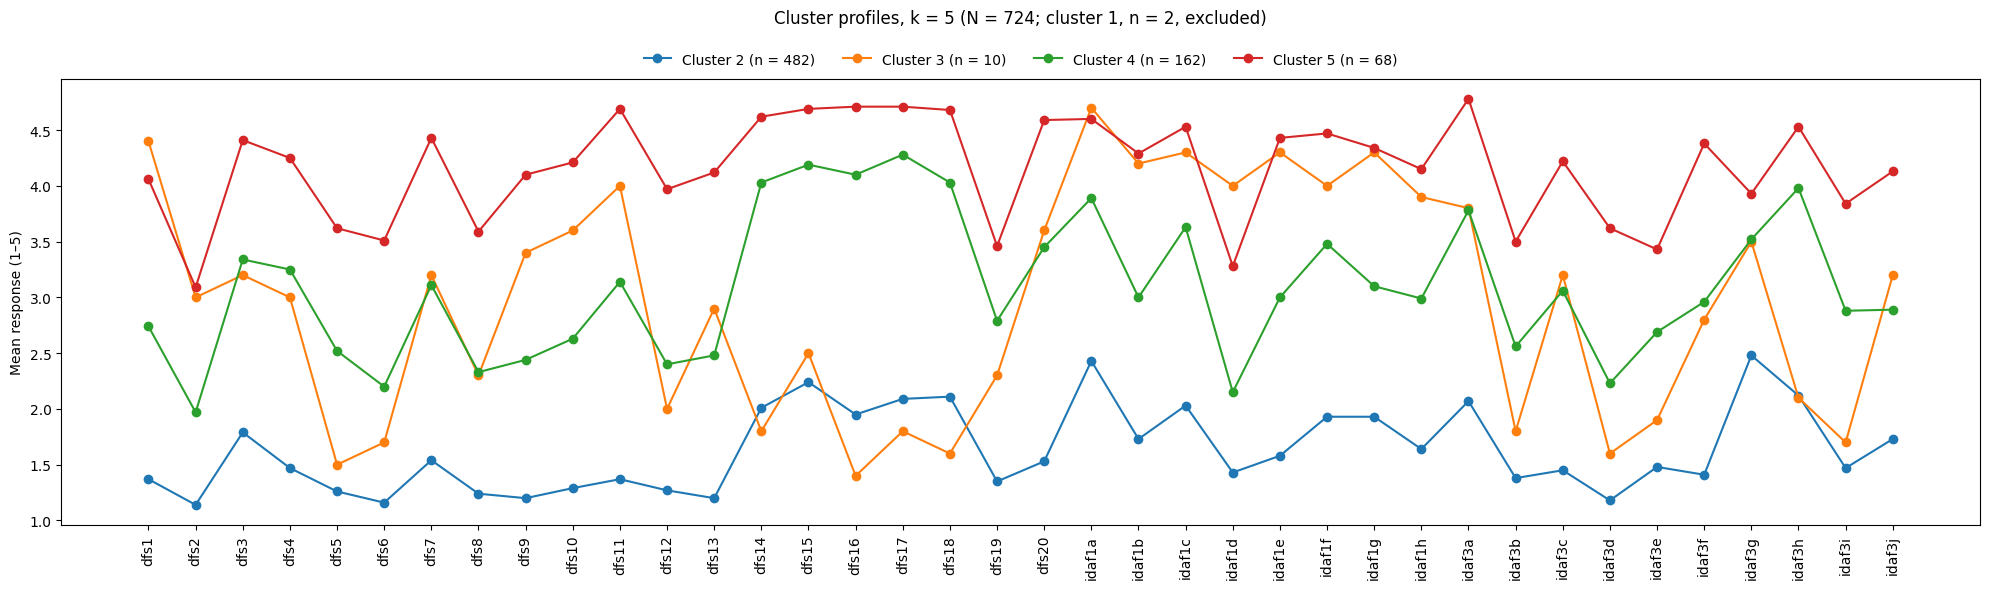

In [20]:
sizes = prof.loc["n"] if "n" in prof.index else pd.Series(np.bincount(lab5)[1:], index=prof.columns)
plot_df = prof.drop(index="n", errors="ignore").drop(columns=1)

ax = plot_df.plot(figsize=(20, 6), marker="o")
ax.set_xticks(range(len(plot_df))); ax.set_xticklabels(plot_df.index, rotation=90)
ax.set_ylabel("Mean response (1–5)")
ax.set_title(f"Cluster profiles, k = 5 (N = {int(sizes.sum())}; cluster 1, n = {int(sizes[1])}, excluded)", pad=40)

# ax.legend([f"Cluster {c} (n = {int(sizes[c])})" for c in plot_df.columns], title="Cluster")
ax.legend(
    [f"Cluster {c} (n = {int(sizes[c])})" for c in plot_df.columns],
    # title="Cluster", 
    loc="lower center", 
    bbox_to_anchor=(0.5, 1.0),      
    ncol=len(plot_df.columns), 
    frameon=False
)
plt.tight_layout()
plt.savefig('figures/profile_analysis.png')
plt.show()

#### Visualize clusters 4 & 5

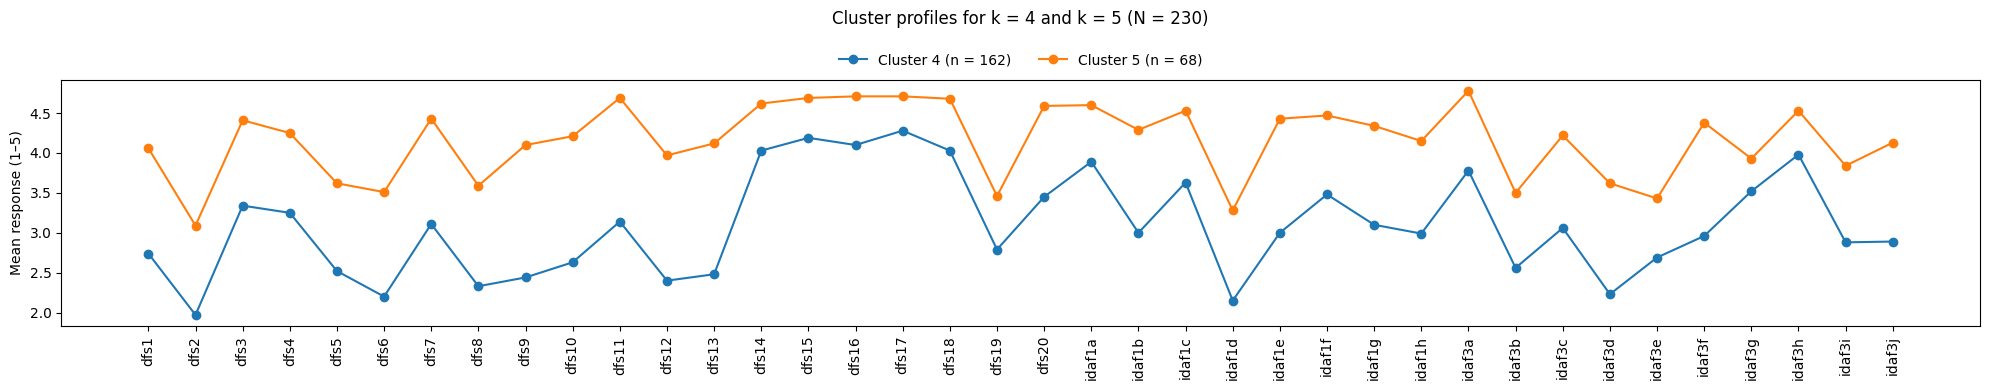

In [21]:
sizes = prof.loc["n"] if "n" in prof.index else pd.Series(np.bincount(lab5)[1:], index=prof.columns)
plot45_df = prof.drop(index="n", errors="ignore")[[4,5]]

ax = plot45_df.plot(figsize=(20, 4), marker="o")
ax.set_xticks(range(len(plot45_df))); ax.set_xticklabels(plot45_df.index, rotation=90)
ax.set_ylabel("Mean response (1–5)")
ax.set_title(f"Cluster profiles for k = 4 and k = 5 (N = {int(sizes[3:].sum())})", pad=40)

ax.legend(
    [f"Cluster {c} (n = {int(sizes[c])})" for c in plot45_df.columns],
    loc="lower center", 
    bbox_to_anchor=(0.5, 1.0),      
    ncol=len(plot_df.columns), 
    frameon=False
)
plt.tight_layout()
plt.savefig('figures/profile_analysis_clusters_4_5.png')
plt.show()

#### Compare clusters 4 & 5  
Clusters 4 & 5 seem visually similar. Compare similarities by plitting the difference between two profiles into three parts:
* **Level (elevation):** is one profile simply higher overall?
* **Scatter:** does one profile vary more from item to item?
* **Shape (pattern):** do the profiles rise and fall on the same items?

#### Descriptive measures from the mean profiles 
How to interpret it:
* **Shape correlation:** a value above 0.8 means the profiles move together.
* **SD of the differences:** if cluster 5 is cluster 4 shifted up, every item gets about the same boost, so the differences are nearly constant and their SD is small.
* **The decomposition:** if elevation accounts for most of D², say 80% or more, the clusters differ mainly in severity.

In [22]:
a, b = plot45_df[4], plot45_df[5]
k = len(a)

r = np.corrcoef(a, b)[0, 1]                # shape similarity, ignores level and spread
d = b - a
print(f"shape r = {r:.3f}")
print(f"mean level difference = {d.mean():.2f}   SD of differences = {d.std():.2f}")

# Cronbach–Gleser decomposition of D² = Σ(b − a)²
sa, sb = a.std(ddof=0), b.std(ddof=0)
elev    = k * d.mean()**2
scatter = k * (sa - sb)**2
shape   = 2 * k * sa * sb * (1 - r)
D2 = elev + scatter + shape
print(pd.Series({"elevation": elev, "scatter": scatter, "shape": shape}) / D2)   # proportions

shape r = 0.837
mean level difference = 1.07   SD of differences = 0.35
elevation    0.903782
scatter      0.022465
shape        0.073753
dtype: float64


Cluster 5 is mostly a more severe version of cluster 4, not a different type of fear.

**Reading the numbers**

* **Shape r = 0.84:** the two profiles rise and fall on largely the same items.
* **Elevation = 90% of the squared distance:** almost all of the difference between the clusters is overall level. Cluster 5 is about 1.07 points higher on average.
* **SD of differences = 0.35:** the boost is fairly consistent across items. Most items differ by roughly 0.7 to 1.4 points.
* **Scatter = 2%:** both clusters spread across items to about the same degree.
* **Shape = 7%:** a small part of the difference is pattern, not level.

That 7% is understated, if anything. Cluster 5 sits at the ceiling on the needle and drill items (about 4.7), so it can’t rise as much there as on other items. That ceiling effect itself creates some apparent non-parallelism.

#### Cluster 3 seems most different  
Check cluster 3 against cluster 4.  
A low or negative shape correlation, with shape making up a large share of the squared distance, would confirm that the avoidant-anticipatory pattern is different in kind. Cluster 3 has only 10 people, so bootstrap that correlation before relying on it.

In [23]:
a, b = plot_df[4], plot_df[3]
k = len(a)

r = np.corrcoef(a, b)[0, 1]                # shape similarity, ignores level and spread
d = b - a
print(f"shape r = {r:.3f}")
print(f"mean level difference = {d.mean():.2f}   SD of differences = {d.std():.2f}")

# Cronbach–Gleser decomposition of D² = Σ(b − a)²
sa, sb = a.std(ddof=0), b.std(ddof=0)
elev    = k * d.mean()**2
scatter = k * (sa - sb)**2
shape   = 2 * k * sa * sb * (1 - r)
D2 = elev + scatter + shape
print(pd.Series({"elevation": elev, "scatter": scatter, "shape": shape}) / D2)   # proportions

shape r = 0.019
mean level difference = -0.12   SD of differences = 1.18
elevation    0.011133
scatter      0.098448
shape        0.890419
dtype: float64


#### Uncertainty: bootstrap the shape correlation (clusters 4 & 5)
Resamples respondents within each cluster and recomputes the correlation each time.

In [24]:
items = plot45_df.index
X4 = subset_df.loc[lab5 == 4, items].to_numpy()
X5 = subset_df.loc[lab5 == 5, items].to_numpy()
rng = np.random.default_rng(0)
boot = [np.corrcoef(X4[rng.integers(0, len(X4), len(X4))].mean(0),
                    X5[rng.integers(0, len(X5), len(X5))].mean(0))[0, 1] for _ in range(2000)]
print("shape r 95% CI:", np.percentile(boot, [2.5, 97.5]).round(3))

shape r 95% CI: [0.707 0.873]


The shape similarity holds up under resampling. Even the low end of the interval (0.71) is a strong correlation, so the conclusion that cluster 5 is mostly a more severe cluster 4 does not depend on which respondents happen to be in the sample.

#### Testing parallelism  
Subtract each person’s own mean from their responses, which removes level. Then use a permutation test to ask whether the two clusters’ adjusted mean profiles differ more than random group assignments would produce.  

`dev` lists the items where cluster 5 is relatively higher or lower than its overall shift would predict. From your plot, expect cluster 5 to stand out on avoidance (dfs1–2) and on disgust and embarrassment (idaf3b, 3d, 3i, dfs6). Expect it to fall below the parallel line on needles and drills, where it’s already near the ceiling.

**Two caveats**  

* **Ceiling effect:** cluster 5 sits around 4.6–4.7 on the stimulus items, with a maximum of 5. It can’t rise as much there as on other items, so the profiles can’t be perfectly parallel even if the underlying fear is. This deflates the shape similarity, so rely more on the correlation than on the parallelism test.
* **Circularity:** the clusters were formed to differ on these same items. Treat the permutation p-value as descriptive, not inferential. A firm conclusion needs a replication sample, or the same pattern turning up in LCA classes.

In [25]:
def ipsatize(X): return X - X.mean(1, keepdims=True)
Y = np.vstack([ipsatize(X4), ipsatize(X5)]); g = np.r_[np.zeros(len(X4)), np.ones(len(X5))]
stat = lambda g: ((Y[g == 0].mean(0) - Y[g == 1].mean(0))**2).sum()
obs = stat(g)
perm = [stat(rng.permutation(g)) for _ in range(5000)]
print(f"shape-difference statistic = {obs:.5f}, permutation p = {np.mean(np.array(perm) >= obs):.5f}")

# which items depart most from parallel
dev = pd.Series(Y[g == 1].mean(0) - Y[g == 0].mean(0), index=items).sort_values()
print(dev.round(3))

shape-difference statistic = 4.67862, permutation p = 0.00000
idaf3g   -0.670
dfs17    -0.643
dfs15    -0.565
idaf3h   -0.524
dfs14    -0.485
dfs16    -0.471
dfs18    -0.426
dfs19    -0.406
idaf1a   -0.357
idaf3e   -0.336
idaf1c   -0.172
idaf3b   -0.133
idaf3i   -0.110
idaf1f   -0.076
idaf3a   -0.076
dfs4     -0.068
dfs3      0.001
dfs5      0.021
dfs2      0.048
idaf1d    0.060
dfs20     0.066
idaf3c    0.087
idaf1h    0.088
idaf1g    0.168
idaf3j    0.172
dfs8      0.183
idaf1b    0.223
dfs6      0.240
dfs7      0.244
dfs1      0.247
idaf3d    0.318
idaf3f    0.354
idaf1e    0.355
dfs11     0.484
dfs12     0.504
dfs10     0.505
dfs13     0.565
dfs9      0.587
dtype: float64


The profiles of clusters 4 and 5 are not perfectly parallel: there is a real shape difference. It’s small compared with the difference in level, and it points somewhere slightly different

**The test**

None of the 5,000 permutations reached the observed statistic, so report it as p < 0.0002 rather than 0.0000. With about 230 respondents, even a modest shape difference is detectable. This fits the earlier decomposition: shape made up about 7% of the squared distance, small but real. The circularity caveat still applies (the clusters were built from these same items), so treat the p-value as descriptive.

**Interpretation**

What cluster 4 fears is the procedures. Cluster 5 shares that fear, already near the ceiling. What it adds is fear of the whole dental context: getting to the office, the waiting room, the chair, the smell, seeing the dentist. It also adds more avoidance, uncertainty and disgust. The move from moderate to severe fear looks like generalization, from specific procedures to everything around the visit.

Two parts of the pattern need qualifying:

* **Needle and drill items:** these are negative partly because of the ceiling. Cluster 5 is at about 4.7 and can’t rise much further, so those values understate its fear.
* **Cost:** it barely changes with severity, which fits the item clustering, where cost was separate from fear.

#### pairwise comparisions

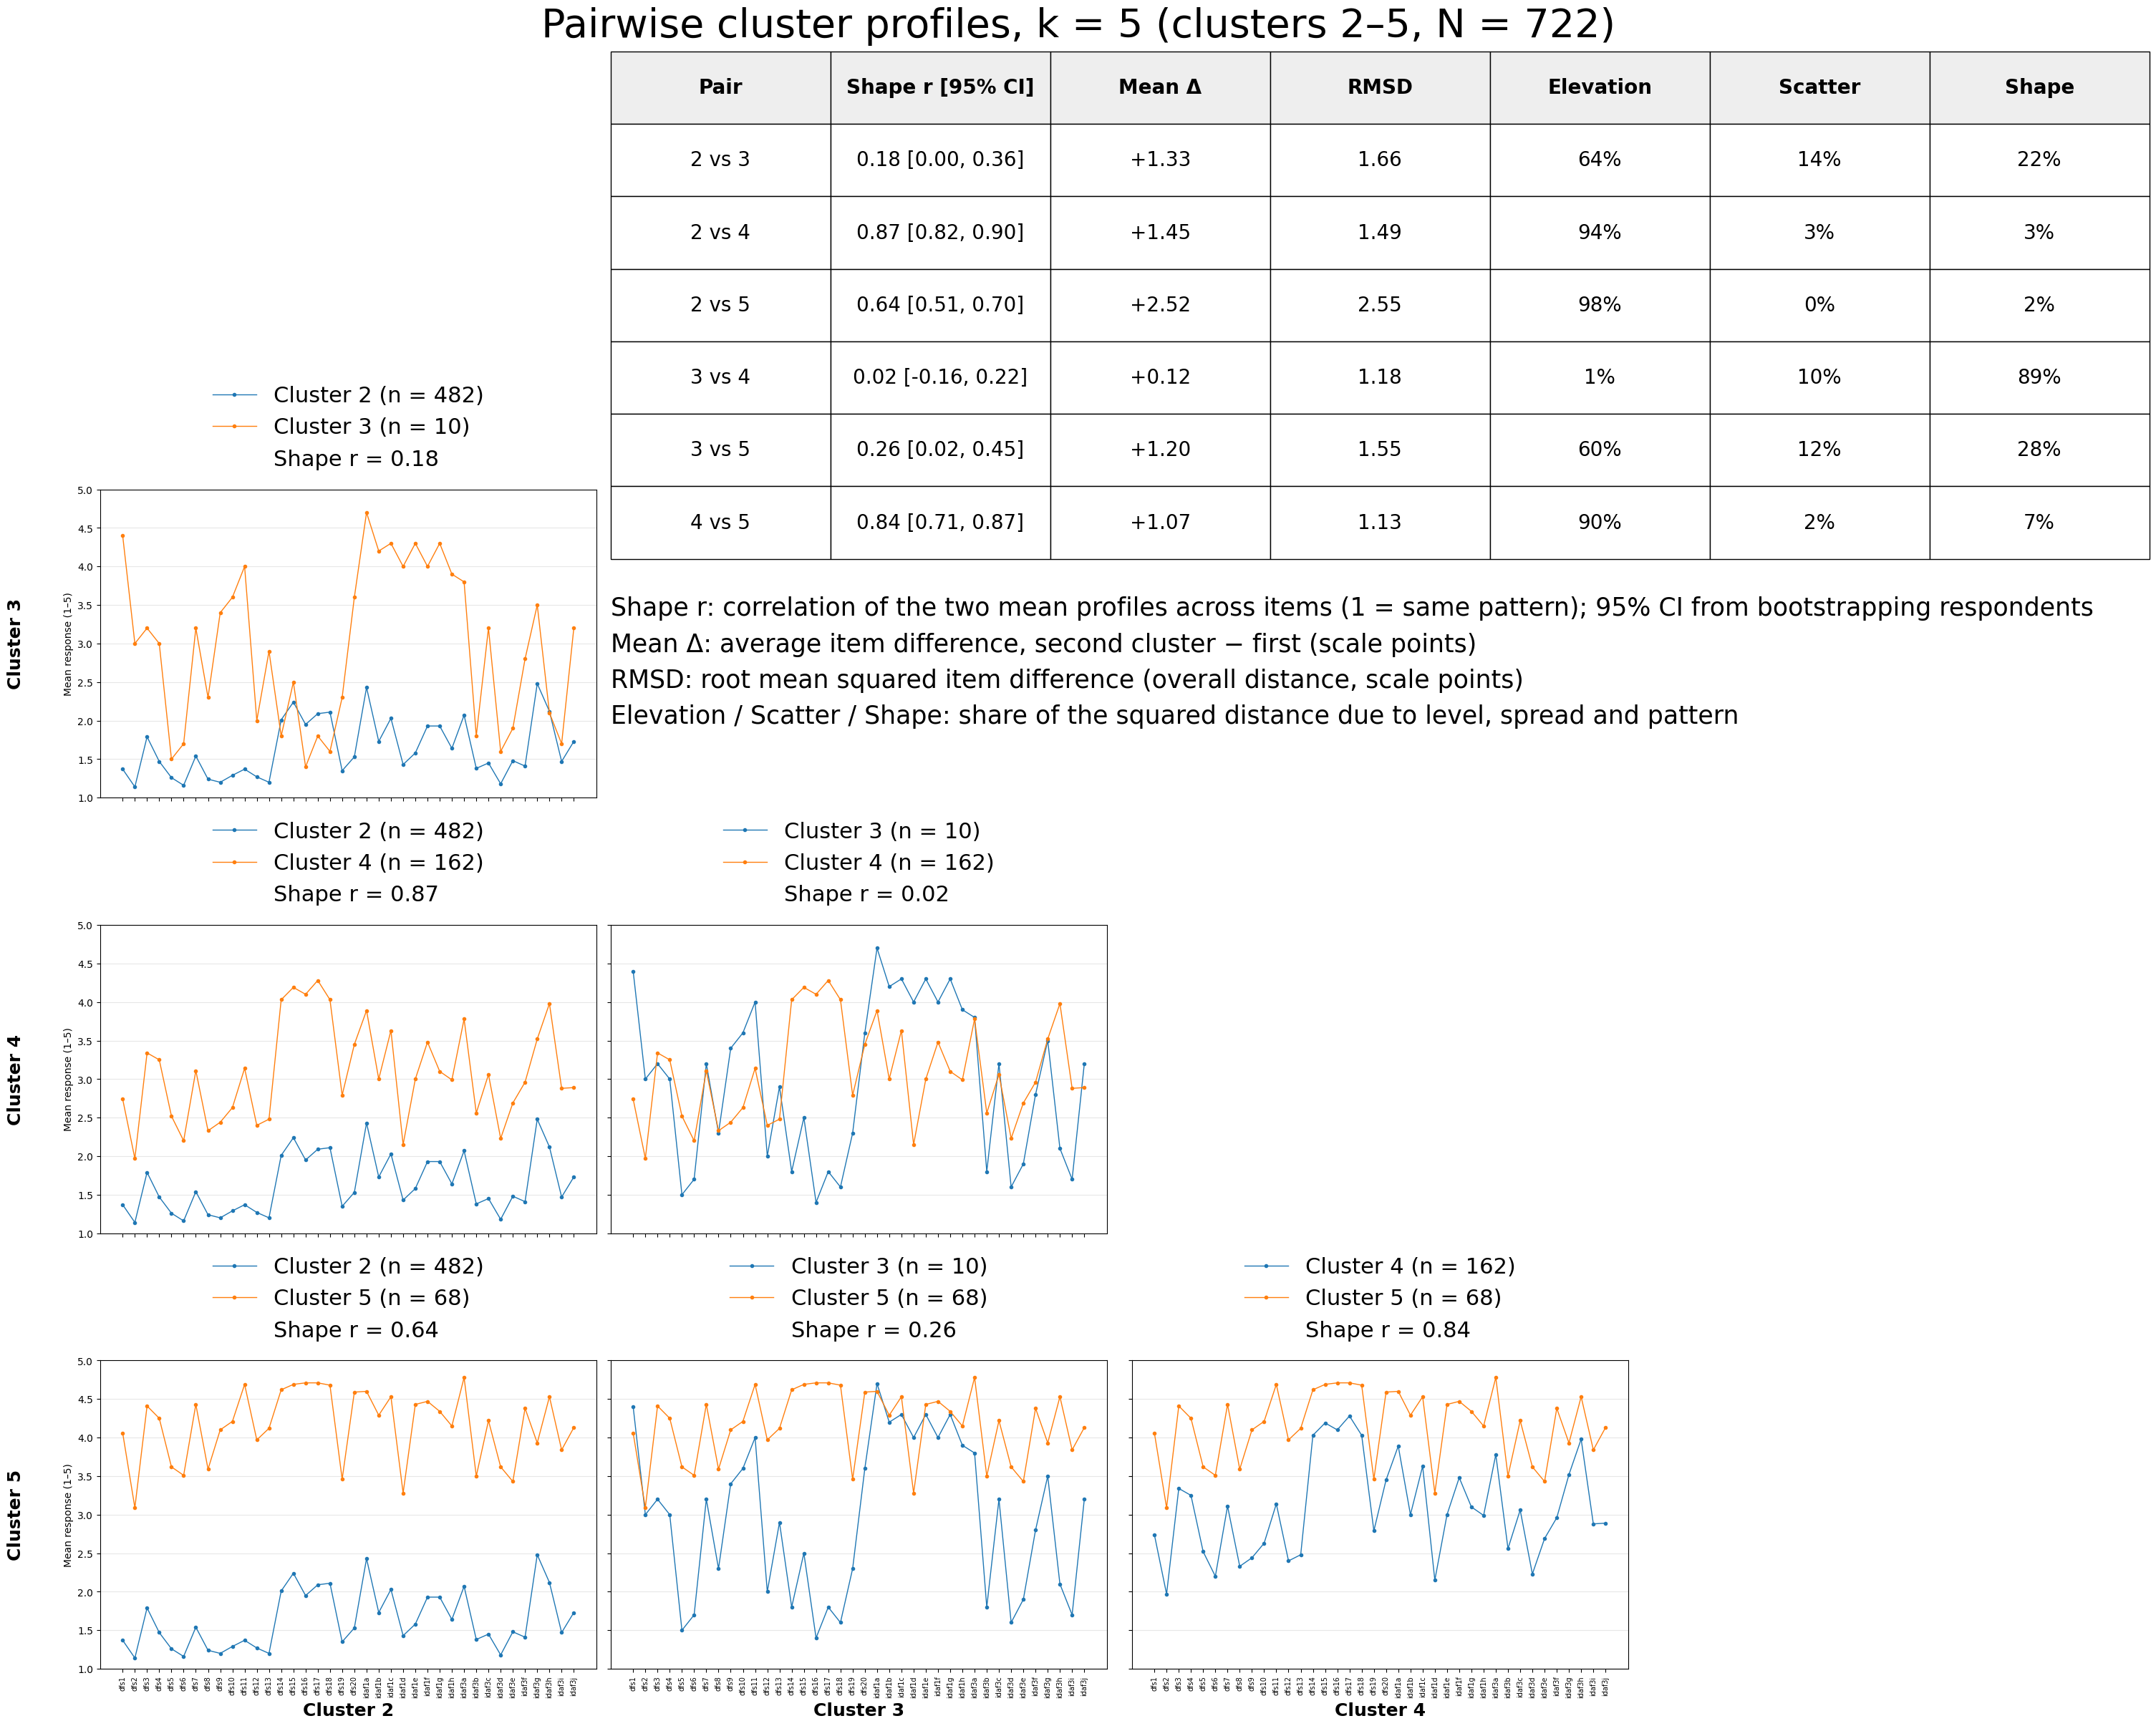

In [26]:
# compare clusters 2–5 from the k = 5 solution; cluster 1 (n = 2) is excluded, as in the profile plot above
k_pairs = 5
pair_clusters = list(range(2, 6))

prof_k, lab_k = cluster_profiles(subset_df, Z, k_pairs)

# similarity scores for each pair of clusters: shape r goes in each panel's legend,
# and the full set is shown as a table in the empty upper-right area
sim_df = pairwise_similarity_table(subset_df, lab_k, pair_clusters)

fig = plot_pairwise_profiles(
    prof_k, pair_clusters,
    figsize=(30, 24),     # (width, height) in inches; None sizes it from panel_size
    legend_fontsize=22,   # font size of the "Cluster c (n = ...)" legend entries
    sim_df=sim_df,        # adds "Shape r = ..." under the clusters in each legend
)

add_similarity_table(
    fig, 
    sim_df,
    fontsize=20,       # font size of the table
    key_fontsize=25,   # font size of the metric descriptions under the table
)

n_shown = int(prof_k.loc["n", pair_clusters].sum())
fig.suptitle(
    f"Pairwise cluster profiles, k = {k_pairs} (clusters {pair_clusters[0]}–{pair_clusters[-1]}, N = {n_shown})",
    fontsize=40
)
plt.savefig(f'figures/pairwise_profile_analysis_k{k_pairs}.png', bbox_inches="tight")
plt.show()

---

### Item clustering: distance = 1 - Spearman correlation

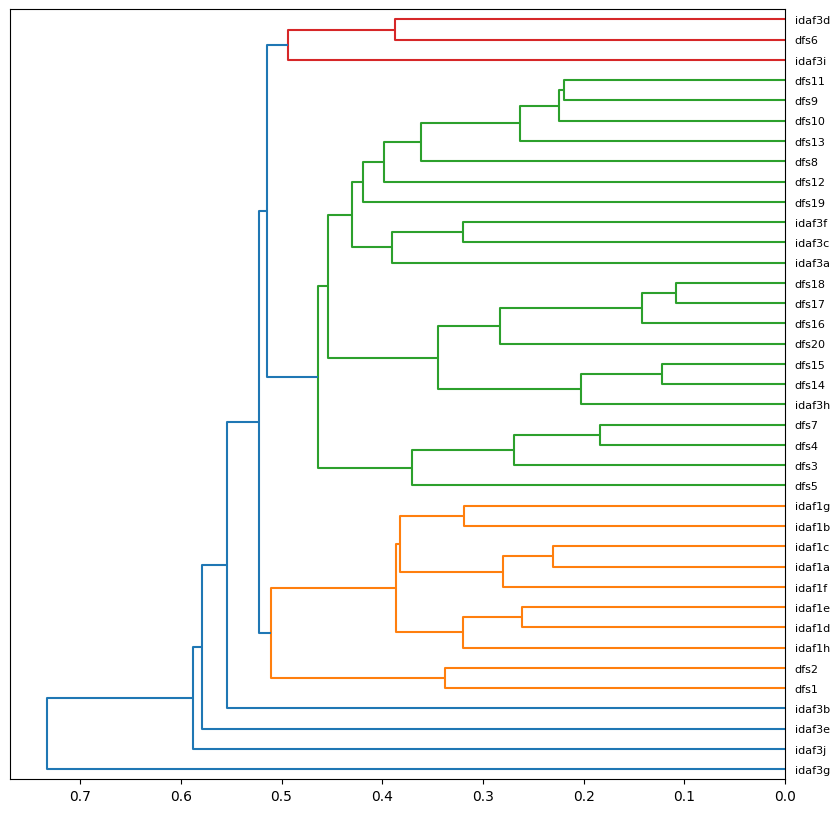

In [27]:
R = subset_df.corr(method="spearman")
Zi = linkage(squareform(1 - R, checks=False), method="average")
fig, ax = plt.subplots(figsize=(10, 10))          # width, height in inches
dendrogram(Zi, labels=subset_df.columns, orientation="left", ax=ax)
plt.savefig('figures/dfs_idaf_item_dendrogram.png')
plt.show()

---

## Hierarchical Clustering of DFS and IDAF-4C+ Items

*Interpretation of the item-level dendrogram — Ontology of Dental Care-Related Fear and Anxiety (ODFA)*

## Analysis

Items from the Dental Fear Survey (DFS, items 1–20) and the Index of Dental Anxiety and Fear (IDAF-4C+) were clustered using average-linkage hierarchical clustering with distance defined as 1 − Spearman ρ. The IDAF-4C+ items included were the core fear-and-anxiety module (IDAF-4C, items 1a–1h) and the stimulus module (IDAF-S, items 3a–3j); the phobia module (IDAF-P, items 2a–2e) was excluded because it is binary and was administered to only a subset of IDAF respondents. The sample comprised participants with complete responses on both instruments.

Merge heights on the horizontal axis are distances: a merge at 0.2 corresponds to ρ ≈ 0.8 and a merge at 0.5 to ρ ≈ 0.5.

![Average-linkage dendrogram of DFS and IDAF-4C/IDAF-S items](./figures/dfs_idaf_item_dendrogram.png)

*Figure 1. Average-linkage dendrogram of DFS and IDAF-4C/IDAF-S items (distance = 1 − Spearman ρ).*

## Summary

The combined analysis reproduces the DFS structure found when DFS items were clustered alone, and several IDAF-S stimulus items attach to clinically meaningful DFS branches, providing cross-instrument convergent validity. Three findings are new: a nausea/disgust/gag component that spans both instruments, a link between the DFS behavioral-avoidance items and the IDAF-4C block, and the near-complete independence of cost from all fear items.

## Structure replicated from the DFS-only analysis

- **Physiological arousal:** DFS 3, 4, 7 (muscle tension, breathing, heart rate) with DFS 5 (perspiring) joining later.
- **Needle and drill stimuli:** DFS 14–15 (needle) and DFS 16–18 (drill), with the global fear item DFS 20 attaching to the drill branch.
- **Situational/anticipatory fear:** DFS 8–13 (making an appointment, travelling, waiting room, chair, smell, seeing the dentist).
- **Behavioral avoidance:** DFS 1–2 (putting off visits, cancelling appointments) remain separate from the other DFS items.

## Cross-instrument convergence

| Items | Merge distance | Interpretation |
|---|---|---|
| IDAF 3h (needles) with DFS 14, 15 | ≈ 0.21 | Strongest cross-instrument pairing; both instruments measure the same needle fear. |
| IDAF 3a (painful procedures) to needle/drill branch | ≈ 0.40 | Pain concern sits with fear of invasive stimuli. |
| IDAF 3c (loss of control), 3f (not knowing what the dentist will do) to situational DFS branch | ≈ 0.42 | Uncertainty and control appraisals align with anticipatory/situational fear rather than stimulus fear. |
| IDAF 3d (sick/queasy/disgust) with DFS 6 (nausea); IDAF 3i (gagging) joins | 0.39 / 0.51 | A nausea–disgust–gag component distinct from sympathetic arousal (DFS 3–5, 7). |

### Nausea, disgust and gagging

In the DFS-only analysis, DFS 6 (nausea) was the most isolated item. In the combined analysis it pairs with IDAF 3d and is joined by IDAF 3i, forming a small component separate from the arousal items. This suggests that nausea-, disgust- and gag-related responses are a distinct facet of dental fear rather than part of general physiological arousal. The finding is relevant to the critique of classifying DFA as a blood-injection-injury phobia, although clustering alone does not establish the mechanism.

### Behavioral avoidance and the IDAF-4C block

The eight IDAF-4C items form a tight cluster, with the avoidance items IDAF 1b (avoid) and 1g (delay appointments) pairing within it. DFS 1–2 attach to this block (≈ 0.52) rather than to the other DFS items. Behavioral avoidance therefore relates more closely to general anxiety and avoidance appraisals than to fear of particular stimuli or situations. Part of the IDAF-4C cohesion is likely method variance, since its items share one questionnaire, stem and response format.

## Items with little shared variance

Four IDAF-S items join the tree only near the root:

| Item | Merge distance | Comment |
|---|---|---|
| IDAF 3b — feeling embarrassed or ashamed | ≈ 0.55 | Social-evaluative concern, distinct from fear of procedures. |
| IDAF 3e — numbness from the anesthetic | ≈ 0.58 | Weakly related to other triggers. |
| IDAF 3j — unsympathetic or unkind dentist | ≈ 0.59 | Interpersonal concern, weakly related to other triggers. |
| IDAF 3g — cost of dental treatment | ≈ 0.74 | Most isolated item; essentially unrelated to the fear items. |

The independence of cost supports distinguishing cost- or access-driven avoidance from fear-driven avoidance.

## Implications for ODFA

| Finding | Ontology implication |
|---|---|
| Needle, drill and pain items cluster tightly across instruments | Stimulus-specific fear dispositions are well supported. |
| Nausea, disgust and gagging form a separate component | Candidate disgust/gag-related subtype, distinct from arousal. |
| Loss of control and uncertainty align with situational fear | Cognitive appraisals of the visit belong with anticipatory fear. |
| Cost is unrelated to fear items | Cost-driven avoidance is a separate cause of avoidance behavior. |
| Avoidance items separate from fear items | Keep dental care avoidance behavior distinct from the DFA disposition. |

## Caveats

- **Sample size.** The analysis uses only the DFS–IDAF overlap sample, which is much smaller than the DFS-only sample.
- **Different question stems.** IDAF-S asks how much a factor contributes to the respondent's fear, whereas DFS asks how afraid they are of a situation or stimulus. Close pairings such as IDAF 3h with DFS 14–15 are therefore more persuasive than distances between loosely related items.
- **Method variance.** Items from the same instrument and response format correlate partly for that reason alone, which inflates within-instrument cohesion (notably for IDAF-4C).
- **Correlation measure.** Spearman correlations on 5-point items with strong floor effects understate associations; polychoric correlations would be higher, though the pattern is expected to be similar.
- **Exploratory method.** Hierarchical clustering describes structure but does not test it.

## Recommended next steps

- Fit an ordinal confirmatory factor analysis (e.g., lavaan with `ordered = TRUE`) comparing the published DFS three-factor model with alternatives that separate behavioral avoidance (DFS 1–2) and a nausea/disgust/gag factor.
- Repeat the clustering with polychoric correlations to confirm the pattern.
- Assess stability by bootstrap resampling of respondents.


---

## SHAP clustering

### Make train and test sets

In [28]:
X, y = subset_df.drop('dfs20', axis=1), subset_df['dfs20']

#### Tune hyperparamaters

In [29]:
param_dist = {
    "n_estimators":      randint(200, 1001),
    "max_depth":         [None, 4, 6, 8, 10, 14],
    "min_samples_leaf":  randint(1, 21),          # larger = smoother, less overfit
    "min_samples_split": randint(2, 21),
    "max_features":      ["sqrt", "log2", 0.3, 0.5],
    "class_weight":      [None, "balanced", "balanced_subsample"],
    "bootstrap":         [True],
}

In [30]:
qwk = make_scorer(cohen_kappa_score, weights="quadratic")

In [31]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [32]:
search_rf = RandomizedSearchCV(
    RandomForestClassifier(random_state=42, n_jobs=-1),
    param_distributions=param_dist,
    n_iter=60,                 # number of random combinations tried
    scoring=qwk,
    cv=cv,
    random_state=0,
    n_jobs=1,                  # the forest already uses all cores; avoid nested parallelism
    verbose=1,
)
search_rf.fit(X, y)

Fitting 5 folds for each of 60 candidates, totalling 300 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestC...ndom_state=42)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'bootstrap': [True], 'class_weight': [None, 'balanced', ...], 'max_depth': [None, 4, ...], 'max_features': ['sqrt', 'log2', ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",60
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",make_scorer(c...hts=quadratic)
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",0
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best es

In [33]:
print("best QWK:", round(search_rf.best_score_, 3))
print("best params:", search_rf.best_params_)

best QWK: 0.849
best params: {'bootstrap': True, 'class_weight': 'balanced', 'max_depth': 4, 'max_features': 'log2', 'min_samples_leaf': 12, 'min_samples_split': 18, 'n_estimators': 352}


In [34]:
# top 10 settings, to see how flat the optimum is
res_df = (
    pd.DataFrame(search_rf.cv_results_)
        .sort_values("rank_test_score")
        [["mean_test_score", "std_test_score", "params"]]
        .head(10)
)
# print(res_df.to_string())
res_df

,mean_test_score,std_test_score,params
29,0.849409,0.025515,"{'bootstrap': True, 'class_weight': 'balanced'..."
44,0.845894,0.027447,"{'bootstrap': True, 'class_weight': 'balanced'..."
2,0.843492,0.025756,"{'bootstrap': True, 'class_weight': 'balanced_..."
50,0.843458,0.028323,"{'bootstrap': True, 'class_weight': 'balanced'..."
19,0.842911,0.035413,"{'bootstrap': True, 'class_weight': 'balanced_..."
21,0.842384,0.033707,"{'bootstrap': True, 'class_weight': 'balanced_..."
11,0.842381,0.029850,"{'bootstrap': True, 'class_weight': 'balanced_..."
22,0.842294,0.029001,"{'bootstrap': True, 'class_weight': 'balanced_..."
15,0.842245,0.034050,"{'bootstrap': True, 'class_weight': 'balanced'..."
35,0.842238,0.037371,"{'bootstrap': True, 'class_weight': 'balanced_..."


In [35]:
rf_model = search_rf.best_estimator_

In [36]:
shap_values = np.zeros(X.shape)
for train_index, test_index in StratifiedKFold(5, shuffle=True, random_state=42).split(X, y):
    m = clone(rf_model).fit(X.iloc[train_index], y.iloc[train_index])
    s = shap.TreeExplainer(m).shap_values(X.iloc[test_index])
    s = np.stack(s, axis=-1) if isinstance(s, list) else s     # → (n, items, classes) in any shap version
    shap_values[test_index] = s @ m.classes_.astype(float)     # SHAP for E[dfs20] = Σ c·P(c)

In [37]:
sv = pd.DataFrame(shap_values, index=X.index, columns=X.columns)

# global importance: which items drive predicted dfs20 overall
imp = sv.abs().mean().sort_values(ascending=False)
print(imp.round(3).head(15))

# total push on predicted fear for each person (≈ predicted E[dfs20] minus the baseline)
sv_total = sv.sum(axis=1)
print(sv_total.describe().round(2))

dfs11     0.137
dfs9      0.123
dfs16     0.100
dfs17     0.098
dfs13     0.082
idaf1e    0.081
idaf3a    0.079
dfs18     0.068
idaf1c    0.064
dfs15     0.047
dfs19     0.047
dfs7      0.046
dfs10     0.044
dfs4      0.040
dfs14     0.038
dtype: float64
count    724.00
mean      -0.49
std        1.02
min       -1.89
25%       -1.38
50%       -0.62
75%        0.33
max        1.79
dtype: float64


In [38]:
D_s = pdist(sv.to_numpy(), metric="euclidean")
Z_s = linkage(sv.to_numpy(), method="ward")
print("cophenetic r:", round(cophenet(Z_s, D_s)[0], 3))

DM_s = squareform(D_s)
for k in range(2, 9):
    lab = fcluster(Z_s, k, criterion="maxclust")
    print(k, round(silhouette_score(DM_s, lab, metric="precomputed"), 3), np.bincount(lab)[1:])

cophenetic r: 0.652
2 0.347 [287 437]
3 0.274 [287 197 240]
4 0.259 [287 197 117 123]
5 0.245 [287  61 136 117 123]
6 0.247 [287  61  59  77 117 123]
7 0.177 [192  95  61  59  77 117 123]
8 0.174 [192  95  61  59  77 117  31  92]


In [39]:
k = 4                                          # choose from step 2
lab_s = fcluster(Z_s, k, criterion="maxclust")

summary = pd.DataFrame({
    "n":              pd.Series(lab_s).value_counts().sort_index(),
    "dfs20_observed": y.groupby(lab_s).mean(),
    "shap_total":     sv_total.groupby(lab_s).mean(),
}).round(2)
print(summary)

drivers  = sv.groupby(lab_s).mean().T.round(2)   # why: which items push predicted fear up or down
profiles = X.groupby(lab_s).mean().T.round(2)    # what: the actual item responses

     n  dfs20_observed  shap_total
1  287            1.15       -1.50
2  197            2.31       -0.36
3  117            4.34        1.08
4  123            2.93        0.16


In [40]:
for c in drivers.columns:
    print(c, drivers[c].sort_values(ascending=False).head(5).round(2).to_dict())

1 {'idaf3j': -0.0, 'dfs6': -0.0, 'idaf3b': -0.0, 'idaf3d': -0.0, 'idaf3g': -0.0}
2 {'dfs16': 0.03, 'dfs18': 0.02, 'dfs17': 0.02, 'dfs15': 0.01, 'idaf3j': -0.0}
3 {'dfs11': 0.13, 'dfs16': 0.11, 'dfs9': 0.1, 'dfs17': 0.09, 'idaf1e': 0.07}
4 {'dfs9': 0.08, 'dfs11': 0.07, 'dfs13': 0.04, 'idaf1c': 0.02, 'dfs1': 0.01}


In [41]:
pd.crosstab(lab_s, lab5, rownames=["SHAP cluster"], colnames=["Hierarchical k=5"])

Hierarchical k=5,1,2,3,4,5
SHAP cluster,,,,,
1,0,287,0,0,0
2,0,146,0,50,1
3,2,1,0,55,59
4,0,48,10,57,8


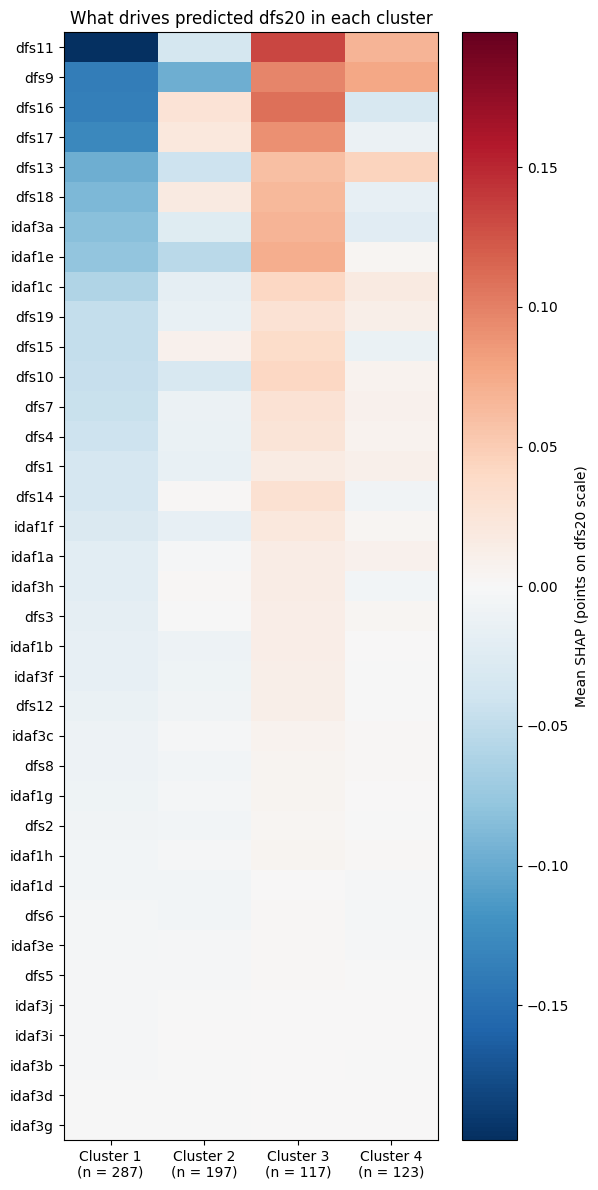

In [42]:
drivers = sv.groupby(lab_s).mean().T                     # items × clusters
drivers = drivers.loc[drivers.abs().max(axis=1).sort_values(ascending=False).index]  # strongest items first
sizes = pd.Series(lab_s).value_counts().sort_index()

lim = np.abs(drivers.values).max()
fig, ax = plt.subplots(figsize=(6, 12))
im = ax.imshow(drivers.values, cmap="RdBu_r", vmin=-lim, vmax=lim, aspect="auto")
ax.set_yticks(range(len(drivers))); ax.set_yticklabels(drivers.index)
ax.set_xticks(range(drivers.shape[1]))
ax.set_xticklabels([f"Cluster {c}\n(n = {sizes[c]})" for c in drivers.columns])
fig.colorbar(im, ax=ax, label="Mean SHAP (points on dfs20 scale)")
ax.set_title("What drives predicted dfs20 in each cluster")
plt.tight_layout() 
plt.show()

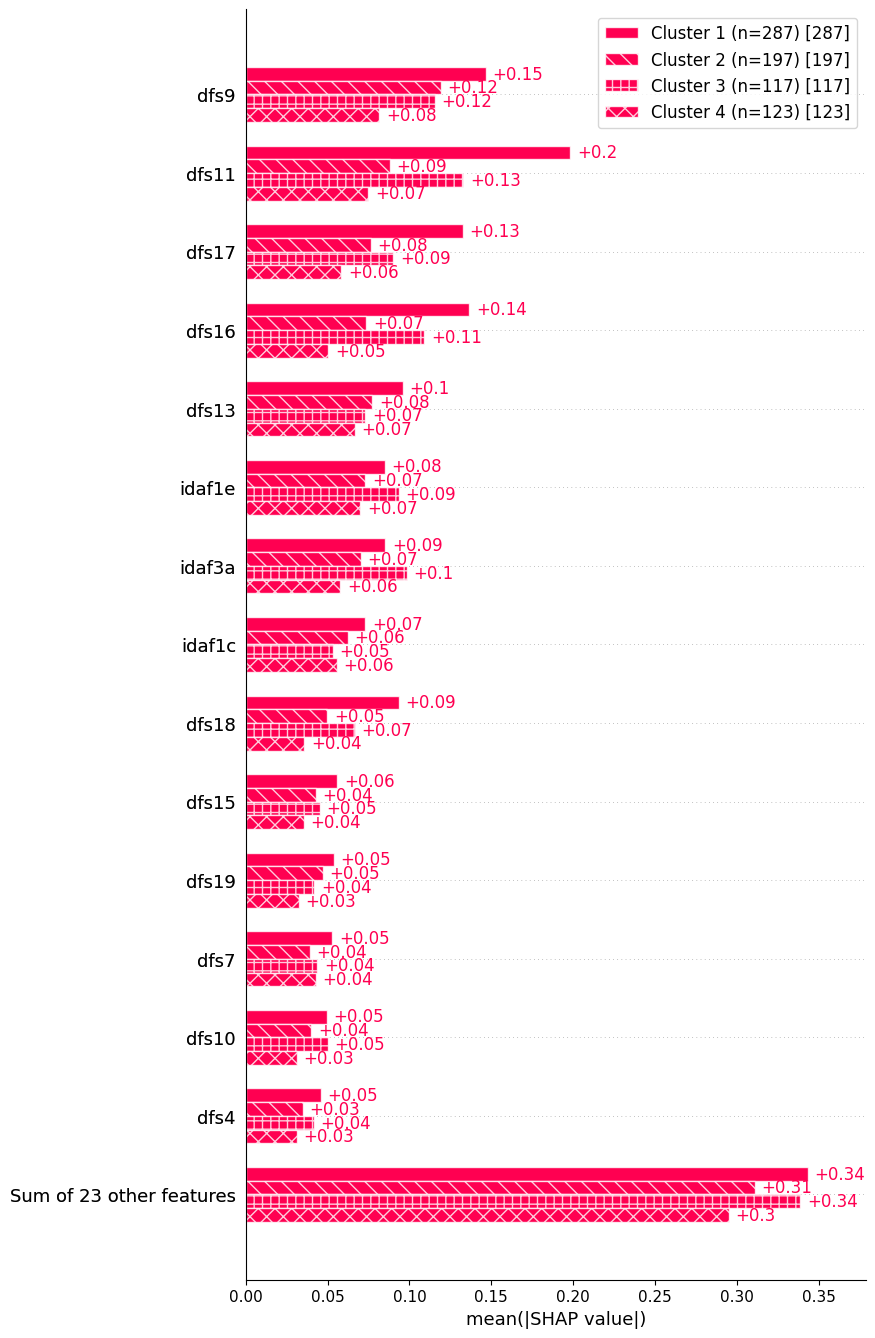

In [43]:
expl = shap.Explanation(values=sv.to_numpy(), data=X.to_numpy(),
                        feature_names=list(X.columns), base_values=np.zeros(len(sv)))
cohorts = np.array([f"Cluster {c} (n={sizes[c]})" for c in lab_s])
shap.plots.bar(expl.cohorts(cohorts).abs.mean(0), max_display=15)

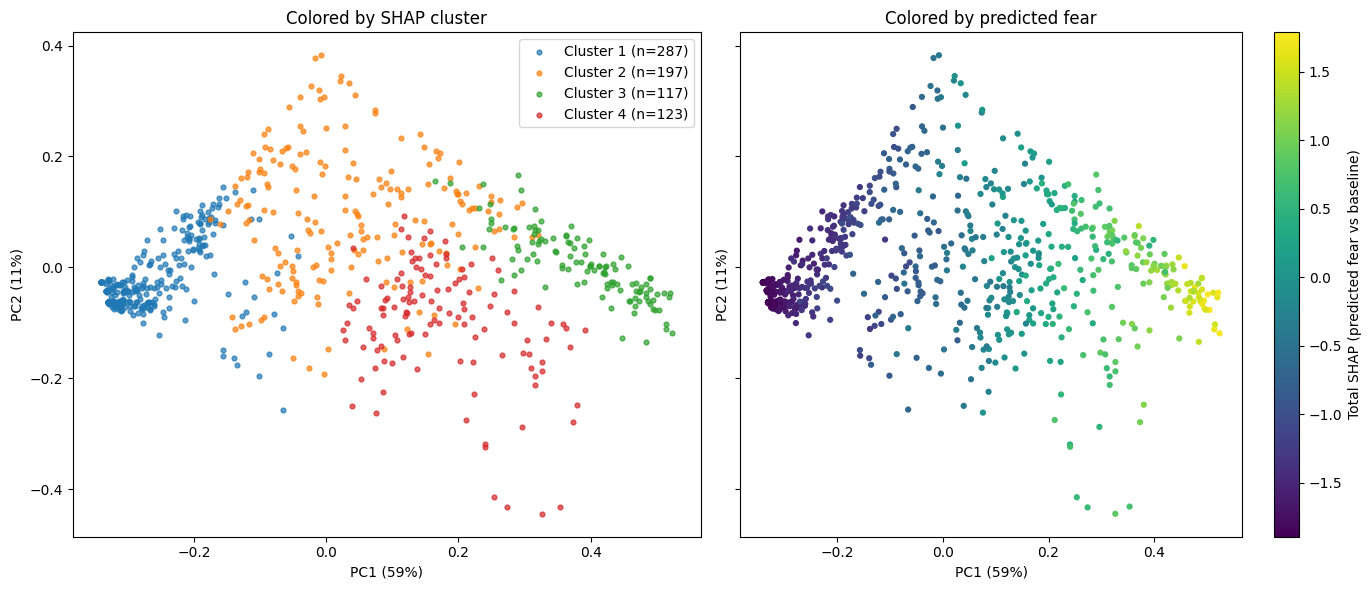

In [49]:
pc = PCA(n_components=2).fit(sv)
xy = pc.transform(sv)

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=True, sharey=True)
for c in np.unique(lab_s):
    axes[0].scatter(*xy[lab_s == c].T, s=12, alpha=0.7, label=f"Cluster {c} (n={sizes[c]})")
axes[0].legend(); axes[0].set_title("Colored by SHAP cluster")
sc = axes[1].scatter(*xy.T, c=sv_total, cmap="viridis", s=12)
fig.colorbar(sc, ax=axes[1], label="Total SHAP (predicted fear vs baseline)")
axes[1].set_title("Colored by predicted fear")
for a in axes: a.set_xlabel(f"PC1 ({pc.explained_variance_ratio_[0]:.0%})"); a.set_ylabel(f"PC2 ({pc.explained_variance_ratio_[1]:.0%})")
plt.tight_layout(); plt.show()

/opt/homebrew/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


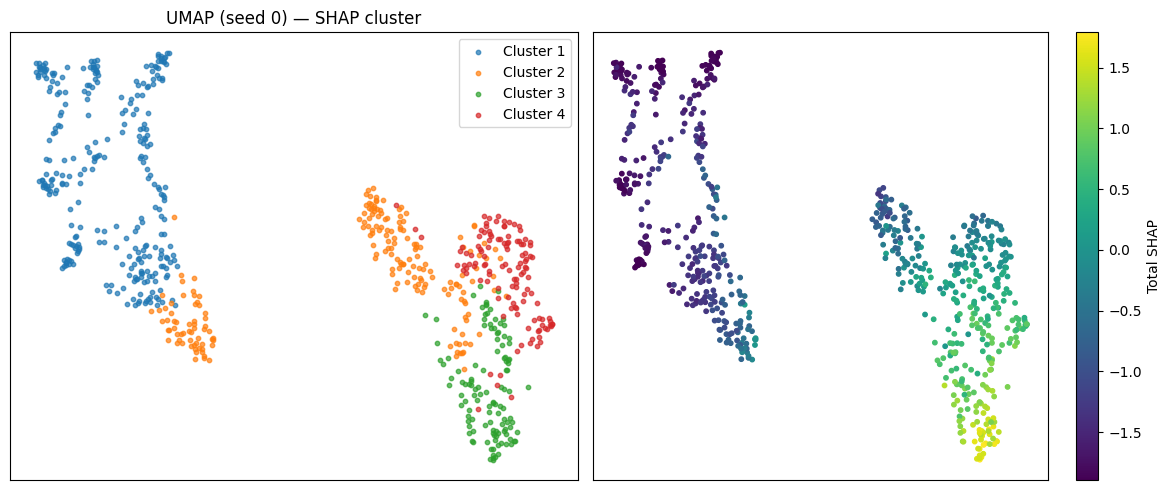

/opt/homebrew/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


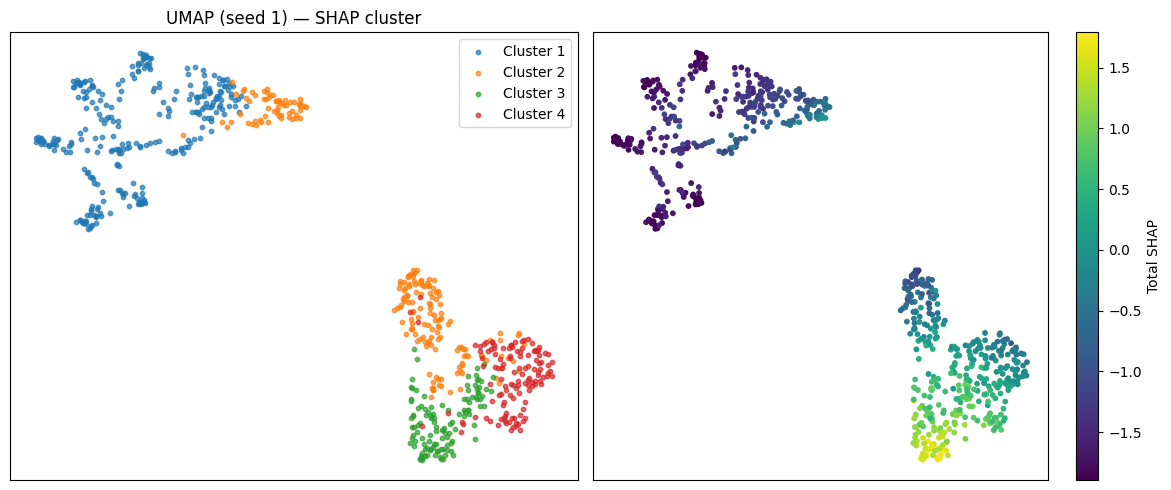

/opt/homebrew/lib/python3.11/site-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


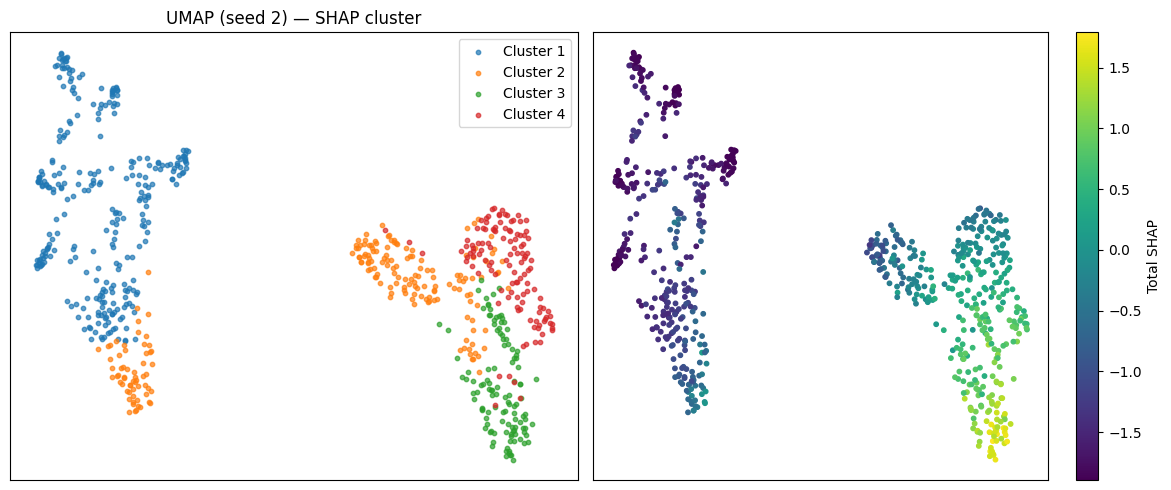

In [48]:
for seed in (0, 1, 2):                                   # check that the picture is stable across seeds
    emb = UMAP(n_neighbors=30, min_dist=0.3, metric="euclidean",
                    random_state=seed).fit_transform(sv)
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for c in np.unique(lab_s):
        axes[0].scatter(*emb[lab_s == c].T, s=10, alpha=0.7, label=f"Cluster {c}")
    axes[0].legend(); axes[0].set_title(f"UMAP (seed {seed}) — SHAP cluster")
    sc = axes[1].scatter(*emb.T, c=sv_total, cmap="viridis", s=10)
    fig.colorbar(sc, ax=axes[1], label="Total SHAP")
    for a in axes: a.set_xticks([]); a.set_yticks([])     # axes carry no meaning
    plt.tight_layout(); plt.show()

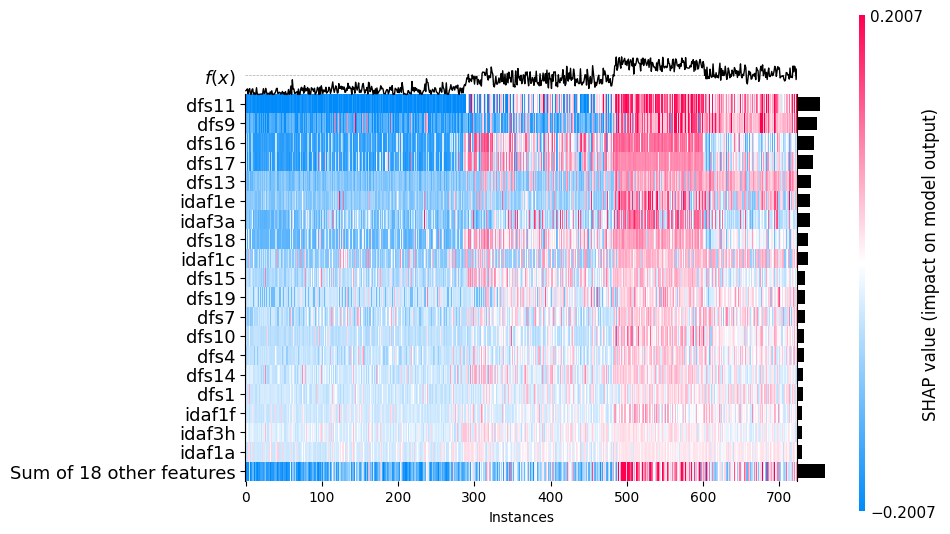

<Axes: xlabel='Instances'>

In [46]:
order = np.argsort(lab_s, kind="stable")
shap.plots.heatmap(expl[order], instance_order=np.arange(len(order)), max_display=20)